# 02 - Backtest Prototype

Train/test a simple rolling z-score breakout idea on 5-minute BTC/USDT data.

In [1]:
from pathlib import Path
import sys

NOTEBOOK_DIR = Path().resolve()
CANDIDATES = [NOTEBOOK_DIR, NOTEBOOK_DIR.parent, NOTEBOOK_DIR.parent.parent]
PROJECT_ROOT = None
for candidate in CANDIDATES:
    if (candidate / 'src' / '__init__.py').exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise RuntimeError('Unable to locate project root containing src/__init__.py')

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.preprocess import clean_and_resample_ohlcv, chronological_train_test_split
from src.signals import rolling_zscore_signal
from src.backtest import run_backtest_with_costs
from src.metrics import (
    sharpe_ratio, max_drawdown, trade_count,
    sharpe_confidence_interval, buy_and_hold_metrics, returns_by_hour_of_day,
)

plt.style.use('seaborn-v0_8')

## Load & resample raw BTC/USDT data
Use the shared helper to clean the 1-minute feed, aggregate to 5-minute bars, and optionally trim the window.

In [2]:
RAW_DATA_PATH = PROJECT_ROOT / 'data/raw/BTCUSDT/btc_2024_raw.csv'
DATE_START = None  # e.g., '2024-01-01'
DATE_END = None    # e.g., '2024-03-01'

df = clean_and_resample_ohlcv(RAW_DATA_PATH, date_start=DATE_START, date_end=DATE_END)
print(f"Loaded {len(df):,} rows spanning {df.index.min()} to {df.index.max()}")
df.head()

[load_raw_ohlcv] Loaded 527,040 rows from C:\Users\joshu\project_2_BTC_trader\data\raw\BTCUSDT\btc_2024_raw.csv
[load_raw_ohlcv] First timestamp: 2024-01-01 00:00:00+00:00
[load_raw_ohlcv] Last timestamp: 2024-12-31 23:59:00+00:00
Loaded 105,408 rows spanning 2024-01-01 00:00:00+00:00 to 2024-12-31 23:55:00+00:00


,open,high,low,close,volume,return,log_return
timestamp,,,,,,,
2024-01-01 00:00:00+00:00,42283.58,42397.23,42261.02,42397.23,155.257,NaN,NaN
2024-01-01 00:05:00+00:00,42397.22,42432.74,42385.26,42409.96,141.311,0.000300,0.000300
2024-01-01 00:10:00+00:00,42409.97,42488.09,42409.96,42488.00,135.143,0.001840,0.001838
2024-01-01 00:15:00+00:00,42488.00,42554.57,42458.58,42458.85,163.324,-0.000686,-0.000686
2024-01-01 00:20:00+00:00,42458.85,42491.10,42445.84,42473.93,117.272,0.000355,0.000355


## Train / test split
Use a chronological 70/30 split to avoid lookahead bias.

In [3]:
TRAIN_FRACTION = 0.7
df_train, df_test = chronological_train_test_split(df, train_fraction=TRAIN_FRACTION)
split_time = df_train.index[-1]

print(f'Train rows: {len(df_train):,}')
print(f'Test rows: {len(df_test):,}')
print(f'Split timestamp: {split_time}')

Train rows: 73,786
Test rows: 31,622
Split timestamp: 2024-09-13 04:45:00+00:00


## Train the z-score signal and backtest

In [4]:
WINDOW = 20
Z_ENTRY = 1.0
COST_PER_UNIT = 0.0005

df_train_sig = rolling_zscore_signal(df_train)
bt_train = run_backtest_with_costs(
    df_train_sig,
    cost_per_unit_change=COST_PER_UNIT,
)
df_train_bt = bt_train.df

sharpe_train = sharpe_ratio(df_train_bt['strategy_return_net'])
dd_train = max_drawdown(df_train_bt['equity_curve_net'])
n_trades_train = trade_count(df_train_bt['position'])

print(f'Train Sharpe (net): {sharpe_train:.3f}')
print(f'Train Max Drawdown (net): {dd_train:.2%}')
print(f'Train # Trades: {n_trades_train}')
print(f"Train total cost: {bt_train.extras['total_cost']:.4f}")

Train Sharpe (net): -73.913
Train Max Drawdown (net): -100.00%
Train # Trades: 33184
Train total cost: 18.5310


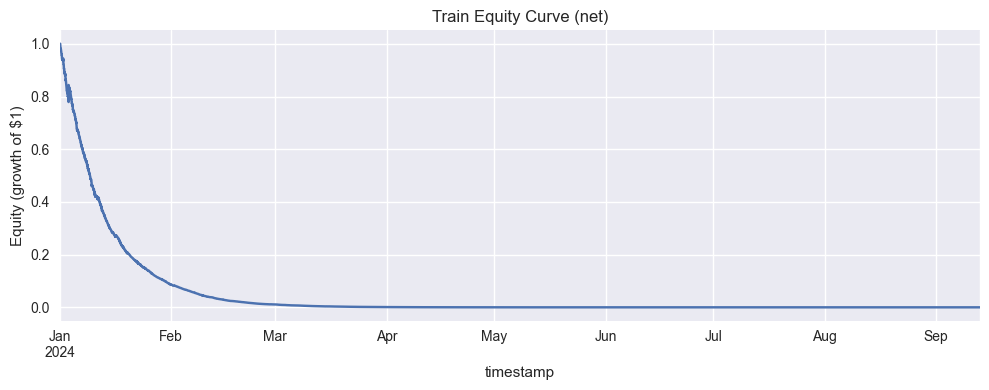

In [5]:
ax = df_train_bt['equity_curve_net'].plot(figsize=(10, 4), title='Train Equity Curve (net)')
ax.set_ylabel('Equity (growth of $1)')
ax.grid(True)
plt.tight_layout()
plt.show()

## Evaluate on the test set (no parameter changes)

In [6]:
df_test_sig = rolling_zscore_signal(df_test, window=WINDOW, z_entry=Z_ENTRY)
bt_test = run_backtest_with_costs(
    df_test_sig,
    cost_per_unit_change=COST_PER_UNIT,
)
df_test_bt = bt_test.df

sharpe_test = sharpe_ratio(df_test_bt['strategy_return_net'])
dd_test = max_drawdown(df_test_bt['equity_curve_net'])
n_trades_test = trade_count(df_test_bt['position'])

print(f'Test Sharpe (net): {sharpe_test:.3f}')
print(f'Test Max Drawdown (net): {dd_test:.2%}')
print(f'Test # Trades: {n_trades_test}')
print(f"Test total cost: {bt_test.extras['total_cost']:.4f}")

Test Sharpe (net): -82.579
Test Max Drawdown (net): -99.96%
Test # Trades: 14564
Test total cost: 8.0790


## Statistical significance and benchmark comparison

Sharpe point estimates are unreliable for short samples. Block bootstrap 95% CIs
show whether the edge is distinguishable from noise. The buy-and-hold baseline
gives context for the gross signal.

In [7]:
bh_train = buy_and_hold_metrics(df_train)
bh_test  = buy_and_hold_metrics(df_test)

ci_train = sharpe_confidence_interval(df_train_bt['strategy_return_net'])
ci_test  = sharpe_confidence_interval(df_test_bt['strategy_return_net'])

summary = pd.DataFrame({
    'metric': ['Sharpe (net)', 'Sharpe CI lower', 'Sharpe CI upper', 'Max DD (net)', 'B&H Sharpe'],
    'train': [
        sharpe_train,
        ci_train[0], ci_train[1],
        dd_train,
        bh_train['sharpe'],
    ],
    'test': [
        sharpe_test,
        ci_test[0], ci_test[1],
        dd_test,
        bh_test['sharpe'],
    ],
}).set_index('metric')

print(summary.to_string(float_format='{:.3f}'.format))
print()
print('If zero is outside the CI, the signal has a statistically detectable edge.')

                  train    test
metric                         
Sharpe (net)    -73.913 -82.579
Sharpe CI lower -79.473 -89.649
Sharpe CI upper -68.471 -74.914
Max DD (net)     -1.000  -1.000
B&H Sharpe        0.798   3.252

If zero is outside the CI, the signal has a statistically detectable edge.


## Cost-aware hysteresis signal

The baseline signal exits positions the moment |z| drops back below the entry
threshold, causing excessive turnover. The hysteresis variant (exit_bandwidth)
holds until |z| crosses a tighter exit level, cutting round-trips while keeping
the same entry logic.

In [8]:
HYSTERESIS_CONFIGS = [
    {'label': 'baseline (no hysteresis)', 'exit_bandwidth': None},
    {'label': 'exit_bw=0.5',              'exit_bandwidth': 0.5},
    {'label': 'exit_bw=0.0 (full rev.)',  'exit_bandwidth': 0.0},
]

hyst_rows = []
for cfg in HYSTERESIS_CONFIGS:
    sig = rolling_zscore_signal(
        df_test, window=WINDOW, z_entry=Z_ENTRY, exit_bandwidth=cfg['exit_bandwidth']
    )
    bt = run_backtest_with_costs(sig, cost_per_unit_change=COST_PER_UNIT)
    df_bt = bt.df
    hyst_rows.append({
        'config': cfg['label'],
        'test_sharpe': sharpe_ratio(df_bt['strategy_return_net']),
        'test_sharpe_ci': str(sharpe_confidence_interval(df_bt['strategy_return_net'])),
        'test_max_dd': max_drawdown(df_bt['equity_curve_net']),
        'test_trades': trade_count(df_bt['position']),
        'test_total_cost': bt.extras['total_cost'],
    })

pd.DataFrame(hyst_rows).set_index('config')

,test_sharpe,test_sharpe_ci,test_max_dd,test_trades,test_total_cost
config,,,,,
baseline (no hysteresis),-82.579022,"(-89.64944496942894, -74.91440207940371)",-0.999619,14564,8.079
exit_bw=0.5,-75.282550,"(-81.81861414460545, -68.32535311783057)",-0.999535,13790,7.839
exit_bw=0.0 (full rev.),-62.485270,"(-68.33062755837426, -56.34933005649852)",-0.999124,12251,7.321


## Intraday time-of-day analysis

Group gross (pre-cost) strategy returns by UTC hour to identify whether the
signal's edge clusters in specific sessions.

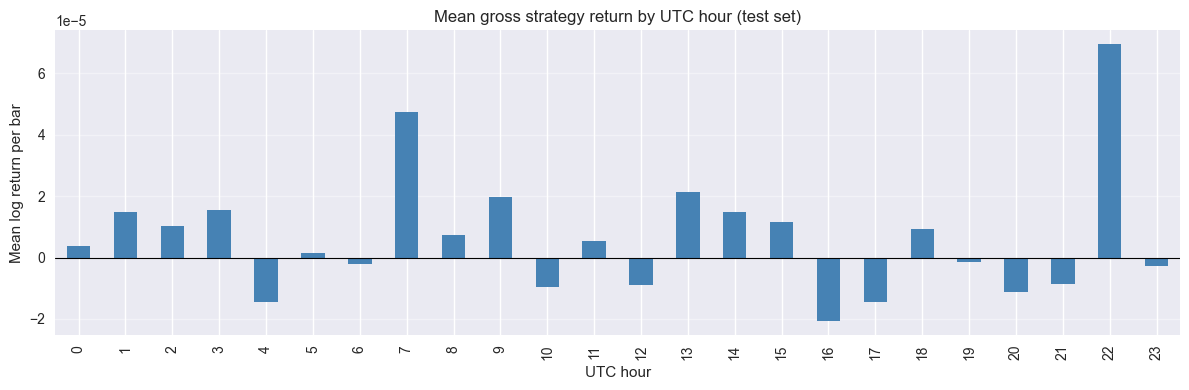

Top 8 UTC hours by mean gross return: [1, 3, 7, 9, 13, 14, 15, 22]


In [9]:
from src.backtest import run_basic_backtest

gross_returns_test = run_basic_backtest(df_test_sig).strategy_returns
hourly = returns_by_hour_of_day(gross_returns_test)

fig, ax = plt.subplots(figsize=(12, 4))
hourly.plot(kind='bar', ax=ax, color='steelblue')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Mean gross strategy return by UTC hour (test set)')
ax.set_xlabel('UTC hour')
ax.set_ylabel('Mean log return per bar')
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

top_hours = hourly.nlargest(8).index.tolist()
print(f'Top 8 UTC hours by mean gross return: {sorted(top_hours)}')

In [10]:
# Restrict signal to the top UTC hours and compare performance
sig_session = rolling_zscore_signal(
    df_test, window=WINDOW, z_entry=Z_ENTRY,
    active_hours=frozenset(top_hours),
)
bt_session = run_backtest_with_costs(sig_session, cost_per_unit_change=COST_PER_UNIT)
df_session = bt_session.df

print('--- Session-filtered signal (test set) ---')
print(f"Sharpe (net):   {sharpe_ratio(df_session['strategy_return_net']):.3f}")
print(f"Sharpe CI:      {sharpe_confidence_interval(df_session['strategy_return_net'])}")
print(f"Max DD (net):   {max_drawdown(df_session['equity_curve_net']):.2%}")
print(f"Trades:         {trade_count(df_session['position'])}")
print(f"Total cost:     {bt_session.extras['total_cost']:.4f}")
print()
print('--- Baseline (all hours) ---')
print(f"Sharpe (net):   {sharpe_test:.3f}  |  Trades: {n_trades_test}")

--- Session-filtered signal (test set) ---
Sharpe (net):   -39.879
Sharpe CI:      (-47.288185695139425, -32.7811793850037)
Max DD (net):   -92.17%
Trades:         5105
Total cost:     2.8330

--- Baseline (all hours) ---
Sharpe (net):   -82.579  |  Trades: 14564


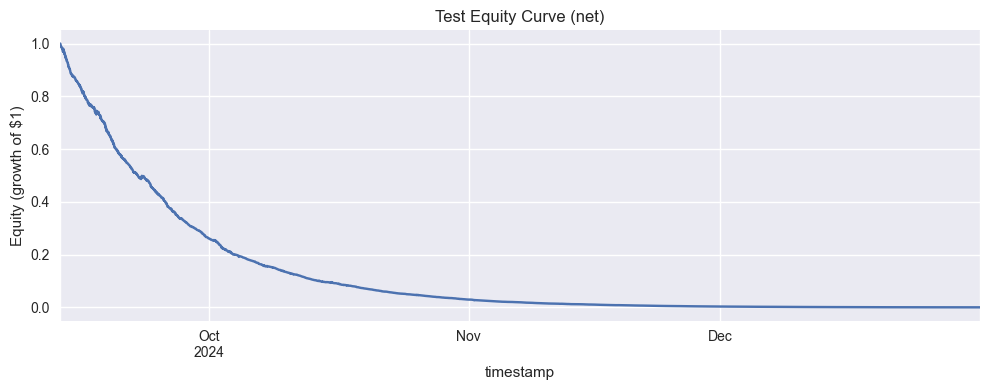

In [11]:
ax = df_test_bt['equity_curve_net'].plot(figsize=(10, 4), title='Test Equity Curve (net)')
ax.set_ylabel('Equity (growth of $1)')
ax.grid(True)
plt.tight_layout()
plt.show()

## Risk overlays: volatility targeting + daily stop-out
Scale the {-1, 0, +1} signal using a rolling volatility estimate and flatten exposure after a -1% day to keep risk roughly constant.

In [12]:
RISK_PARAMS = {
    'max_position_size': 1.5,  # cap leverage at 150% notional
    'target_volatility': 0.003,  # target ~30 bps of vol per 5m bar
    'volatility_lookback': 96,   # ~8 hours of 5m data
    'max_leverage': 1.5,
    'daily_stop_loss': 0.01,     # exit for the rest of the day after -1%
}


In [13]:
bt_train_risk = run_backtest_with_costs(
    df_train_sig,
    cost_per_unit_change=COST_PER_UNIT,
    **RISK_PARAMS,
)
df_train_risk = bt_train_risk.df

bt_test_risk = run_backtest_with_costs(
    df_test_sig,
    cost_per_unit_change=COST_PER_UNIT,
    **RISK_PARAMS,
)
df_test_risk = bt_test_risk.df

def summarize(split, variant, df_backtest):
    return {
        'split': split,
        'variant': variant,
        'sharpe': sharpe_ratio(df_backtest['strategy_return_net']),
        'max_drawdown': max_drawdown(df_backtest['equity_curve_net']),
        'trades': trade_count(df_backtest['position']),
    }

comparison = pd.DataFrame([
    summarize('train', 'raw', df_train_bt),
    summarize('train', 'risk', df_train_risk),
    summarize('test', 'raw', df_test_bt),
    summarize('test', 'risk', df_test_risk),
])
comparison

,split,variant,sharpe,max_drawdown,trades
0,train,raw,-73.913296,-1.000000,33184
1,train,risk,-71.881926,-1.000000,22647
2,test,raw,-82.579022,-0.999619,14564
3,test,risk,-76.542733,-0.999779,10932


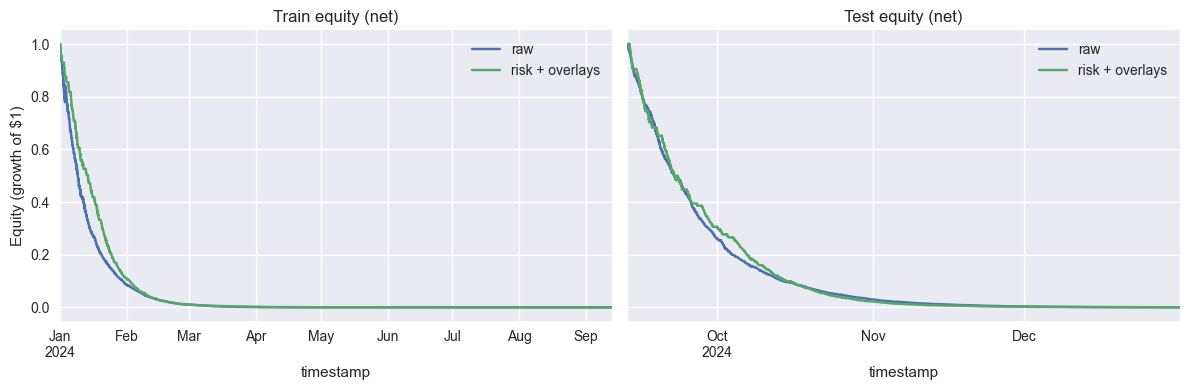

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
df_train_bt['equity_curve_net'].plot(ax=axes[0], label='raw')
df_train_risk['equity_curve_net'].plot(ax=axes[0], label='risk + overlays')
axes[0].set_title('Train equity (net)')
axes[0].set_ylabel('Equity (growth of $1)')
axes[0].grid(True)
axes[0].legend()

df_test_bt['equity_curve_net'].plot(ax=axes[1], label='raw')
df_test_risk['equity_curve_net'].plot(ax=axes[1], label='risk + overlays')
axes[1].set_title('Test equity (net)')
axes[1].grid(True)
axes[1].legend()
plt.tight_layout()
plt.show()

## Overlay parameter sweep
Probe a small grid of volatility targets and daily stop levels to see how the overlays impact the train/test metrics.

In [15]:
from itertools import product

VOL_TARGETS = [0.0025, 0.0030, 0.0035]
DAILY_STOPS = [None, 0.0075, 0.01]
OVERLAY_GRID = []
for i, (vol, stop) in enumerate(product(VOL_TARGETS, DAILY_STOPS), start=1):
    params = {
        'max_position_size': 1.5,
        'target_volatility': vol,
        'volatility_lookback': 96,
        'max_leverage': 1.5,
    }
    if stop is not None:
        params['daily_stop_loss'] = stop
    OVERLAY_GRID.append({
        'name': f'cfg_{i}',
        'target_vol': vol,
        'daily_stop': stop,
        'params': params,
    })

def collect_metrics(split, bt_result):
    df_bt = bt_result.df
    return {
        'split': split,
        'sharpe': sharpe_ratio(df_bt['strategy_return_net']),
        'max_drawdown': max_drawdown(df_bt['equity_curve_net']),
        'trades': trade_count(df_bt['position']),
        'total_cost': bt_result.extras.get('total_cost', 0.0),
    }

records = []
for cfg in OVERLAY_GRID:
    bt_train_cfg = run_backtest_with_costs(
        df_train_sig,
        cost_per_unit_change=COST_PER_UNIT,
        **cfg['params'],
    )
    bt_test_cfg = run_backtest_with_costs(
        df_test_sig,
        cost_per_unit_change=COST_PER_UNIT,
        **cfg['params'],
    )
    for split, bt in (('train', bt_train_cfg), ('test', bt_test_cfg)):
        metrics = collect_metrics(split, bt)
        records.append({
            'config': cfg['name'],
            'target_vol': cfg['target_vol'],
            'daily_stop': cfg['daily_stop'] if cfg['daily_stop'] is not None else 'none',
            **metrics,
        })

overlay_results = (
    pd.DataFrame(records)
    .sort_values(['split', 'sharpe'], ascending=[True, False])
    .reset_index(drop=True)
)
overlay_results

,config,target_vol,daily_stop,split,sharpe,max_drawdown,trades,total_cost
0,cfg_8,0.0035,0.0075,test,-73.546136,-0.999403,9282,7.570445
1,cfg_5,0.0030,0.0075,test,-74.779089,-0.999384,9420,7.579752
2,cfg_2,0.0025,0.0075,test,-75.213209,-0.999358,9835,7.607031
3,cfg_9,0.0035,0.01,test,-75.629047,-0.999789,10745,8.754158
4,cfg_6,0.0030,0.01,test,-76.542733,-0.999779,10932,8.749367
5,cfg_3,0.0025,0.01,test,-78.970336,-0.999761,11205,8.651344
6,cfg_7,0.0035,none,test,-86.534027,-0.999991,14640,11.922286
7,cfg_4,0.0030,none,test,-88.333329,-0.999989,14723,11.776998
8,cfg_1,0.0025,none,test,-90.732039,-0.999986,14899,11.467288
9,cfg_8,0.0035,0.0075,train,-64.903887,-1.000000,19605,15.943130


In [16]:
overlay_results.query("split == 'test'").sort_values('sharpe', ascending=False).reset_index(drop=True)

,config,target_vol,daily_stop,split,sharpe,max_drawdown,trades,total_cost
0,cfg_8,0.0035,0.0075,test,-73.546136,-0.999403,9282,7.570445
1,cfg_5,0.0030,0.0075,test,-74.779089,-0.999384,9420,7.579752
2,cfg_2,0.0025,0.0075,test,-75.213209,-0.999358,9835,7.607031
3,cfg_9,0.0035,0.01,test,-75.629047,-0.999789,10745,8.754158
4,cfg_6,0.0030,0.01,test,-76.542733,-0.999779,10932,8.749367
5,cfg_3,0.0025,0.01,test,-78.970336,-0.999761,11205,8.651344
6,cfg_7,0.0035,none,test,-86.534027,-0.999991,14640,11.922286
7,cfg_4,0.0030,none,test,-88.333329,-0.999989,14723,11.776998
8,cfg_1,0.0025,none,test,-90.732039,-0.999986,14899,11.467288
